# Experimental Analysis

## Experiment Setup

Compare array-backed and linked collections of campus maintenance requests. Request IDs are unique integers; buildings cycle through CASE, ECNW, ECCR, AERO, ATLAS, and NORLIN. The Part G sizes are 1,000, 5,000, 10,000, and 25,000. Data construction is outside each timed interval. The array experiment uses Python's built-in list, including its normal capacity-growth behavior. The random-order input is a repeatable permutation, not a new random sample each run.

The benchmark uses `time.perf_counter()` for middle access, front/middle insertion and removal, append, missing-ID search, linear search, binary search, and insertion sort on sorted, reverse-sorted, and shuffled data. Each operation is timed once; treat tiny differences as approximate. Binary search on a linked list still traverses nodes to access midpoint indexes and is not $O(\log n)$ overall.

## Correctness And Failure Modes

The project's assertion suite passed all 14 tests. It covers empty, one, two, and multiple items; duplicate IDs; successful and unsuccessful search; insertion and removal positions; invalid indexes; and array resizing. This notebook also runs small local ordering and lookup assertions before benchmarking.

A likely bug is an off-by-one shift during array insertion or removal. It could overwrite an item and violate the invariant that live indexes preserve request order. Inserting at index 0 in a two-item collection and then checking every ID exposes it; the project operation tests check these resulting orders. Earlier development tests also caught a misspelled insertion method, zero-capacity resize failure, and empty linked-list append failure.

## Reading The Results

The plots use a logarithmic time axis because slow insertion-sort cases take seconds while most list operations take milliseconds or less. Expect array middle access and sorted-array binary search to scale better than indexed linked-list access; expect array front/middle mutations to shift items. Insertion-sort timings depend strongly on input order and on the linked-sort implementation. The notebook prints every measured observation so trends can be checked against the values.

In [8]:
import time
import matplotlib.pyplot as plt

SIZES = (1000, 5000, 10000, 25000)
BUILDINGS = ("CASE", "ECNW", "ECCR", "AERO", "ATLAS", "NORLIN")


def request(request_id):
    return (request_id, BUILDINGS[request_id % len(BUILDINGS)])


def shuffled_ids(n):
    ids = list(range(n))
    seed = 17
    for i in range(n - 1, 0, -1):
        seed = (1103515245 * seed + 12345) % 2147483648
        j = seed % (i + 1)
        ids[i], ids[j] = ids[j], ids[i]
    return ids


class ArrayList:
    def __init__(self, items):
        self.data = list(items)

    def get(self, i):
        return self.data[i]

    def insert(self, i, item):
        self.data.insert(i, item)

    def append(self, item):
        self.data.append(item)

    def remove(self, i):
        return self.data.pop(i)

    def find(self, target):
        for item in self.data:
            if item[0] == target:
                return item
        return None

    def linear(self, target):
        return self.find(target)

    def binary(self, target):
        low, high = 0, len(self.data) - 1
        while low <= high:
            mid = (low + high) // 2
            if self.data[mid][0] == target:
                return self.data[mid]
            if self.data[mid][0] < target:
                low = mid + 1
            else:
                high = mid - 1
        return None

    def insertion_sort(self):
        for i in range(1, len(self.data)):
            item, j = self.data[i], i - 1
            while j >= 0 and self.data[j][0] > item[0]:
                self.data[j + 1] = self.data[j]
                j -= 1
            self.data[j + 1] = item


class Node:
    def __init__(self, item):
        self.item, self.next = item, None


class LinkedList:
    def __init__(self, items):
        self.head = None
        self.tail = None
        for item in items:
            self.append(item)

    def get(self, i):
        node = self.head
        for _ in range(i):
            node = node.next
        return node.item

    def insert(self, i, item):
        if i == 0:
            node = Node(item)
            node.next, self.head = self.head, node
            if self.tail is None:
                self.tail = node
            return
        previous = self.head
        for _ in range(i - 1):
            previous = previous.next
        node = Node(item)
        node.next, previous.next = previous.next, node
        if node.next is None:
            self.tail = node

    def append(self, item):
        node = Node(item)
        if self.tail is None:
            self.head = self.tail = node
        else:
            self.tail.next, self.tail = node, node

    def remove(self, i):
        if i == 0:
            item, self.head = self.head.item, self.head.next
            if self.head is None:
                self.tail = None
            return item
        previous = self.head
        for _ in range(i - 1):
            previous = previous.next
        item, previous.next = previous.next.item, previous.next.next
        if previous.next is None:
            self.tail = previous
        return item

    def find(self, target):
        node = self.head
        while node:
            if node.item[0] == target:
                return node.item
            node = node.next
        return None

    def linear(self, target):
        return self.find(target)

    def binary(self, target):
        low, high = 0, self.count - 1
        while low <= high:
            mid = (low + high) // 2
            item = self.get(mid)
            if item[0] == target:
                return item
            if item[0] < target:
                low = mid + 1
            else:
                high = mid - 1
        return None

    def insertion_sort(self):
        source, self.head, self.tail = self.head, None, None
        while source:
            node, source = source, source.next
            if self.head is None or node.item[0] < self.head.item[0]:
                node.next, self.head = self.head, node
            else:
                place = self.head
                while place.next and place.next.item[0] < node.item[0]:
                    place = place.next
                node.next, place.next = place.next, node
            if node.next is None:
                self.tail = node

    @property
    def count(self):
        total, node = 0, self.head
        while node:
            total += 1
            node = node.next
        return total


def make_items(n, order="sorted"):
    ids = list(range(n))
    if order == "reverse":
        ids.reverse()
    elif order == "random":
        ids = shuffled_ids(n)
    return [request(i) for i in ids]


def timed(action):
    start = time.perf_counter()
    action()
    return time.perf_counter() - start


def collection(kind, items):
    return ArrayList(items) if kind == "array" else LinkedList(items)


for ListType in (ArrayList, LinkedList):
    sample = ListType([request(i) for i in range(3)])
    sample.insert(1, request(10))
    assert [sample.get(i)[0] for i in range(4)] == [0, 10, 1, 2]
    assert sample.find(-1) is None and sample.find(10)[0] == 10
    assert sample.remove(1)[0] == 10
assert shuffled_ids(1000) != list(range(1000))
print("Local correctness checks passed; deterministic shuffled input is enabled.")

Local correctness checks passed; deterministic shuffled input is enabled.


In [9]:
results = []

for n in SIZES:
    for kind in ("array", "linked"):
        base = make_items(n)
        mid = n // 2
        tests = (
            ("read middle", lambda c: c.get(mid)),
            ("insert beginning", lambda c: c.insert(0, request(n + 1))),
            ("append", lambda c: c.append(request(n + 2))),
            ("insert middle", lambda c: c.insert(mid, request(n + 3))),
            ("remove beginning", lambda c: c.remove(0)),
            ("remove middle", lambda c: c.remove(mid)),
            ("find missing", lambda c: c.find(-1)),
            ("linear search", lambda c: c.linear(-1)),
            ("binary search", lambda c: c.binary(-1)),
        )
        for name, action in tests:
            data = base.copy()
            c = collection(kind, data)
            seconds = timed(lambda: action(c))
            results.append((n, kind, name, seconds))

        for order in ("sorted", "reverse", "random"):
            c = collection(kind, make_items(n, order))
            seconds = timed(c.insertion_sort)
            results.append((n, kind, f"sort {order}", seconds))

print("n      structure operation             seconds")
for n, kind, name, seconds in results:
    print(f"{n:5}  {kind:9} {name:20} {seconds:.8f}")

n      structure operation             seconds
 1000  array     read middle          0.00000357
 1000  array     insert beginning     0.00000424
 1000  array     append               0.00000258
 1000  array     insert middle        0.00000125
 1000  array     remove beginning     0.00000224
 1000  array     remove middle        0.00000054
 1000  array     find missing         0.00003681
 1000  array     linear search        0.00002111
 1000  array     binary search        0.00000534
 1000  array     sort sorted          0.00009879
 1000  array     sort reverse         0.03954559
 1000  array     sort random          0.01908099
 1000  linked    read middle          0.00001185
 1000  linked    insert beginning     0.00000272
 1000  linked    append               0.00000120
 1000  linked    insert middle        0.00001236
 1000  linked    remove beginning     0.00000149
 1000  linked    remove middle        0.00001127
 1000  linked    find missing         0.00007435
 1000  linked    linea

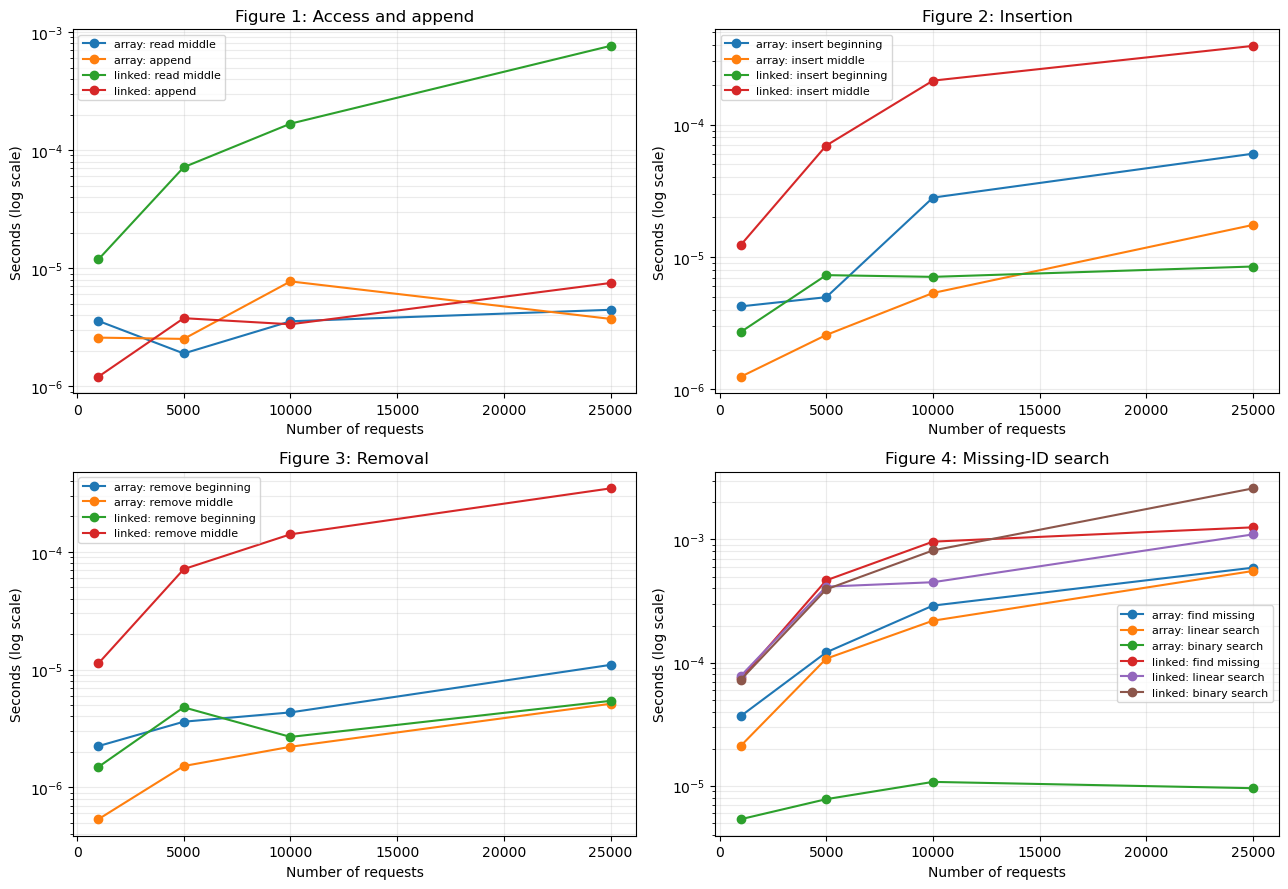

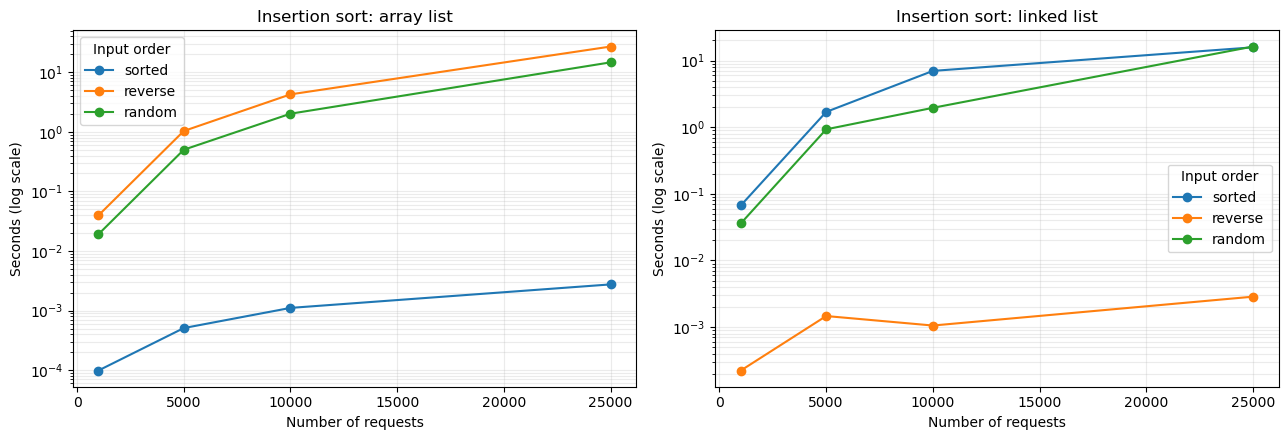

Interpretation: indexed reads and binary search favor arrays; linked middle access and binary search require traversal.
Array front/middle updates shift items. Linked updates avoid shifting but still traverse to reach a middle position.
Insertion sort is fastest on already sorted arrays; reverse/random input takes much longer. Linked sort results depend on its insertion-based algorithm and input order.
Single-run timings are noisy at small durations; compare scaling trends rather than tiny differences.


In [10]:
def plot_lines(operations, title, axis):
    for kind in ("array", "linked"):
        for operation in operations:
            values = [
                next(t for size, structure, name, t in results
                     if size == n and structure == kind and name == operation)
                for n in SIZES
            ]
            axis.plot(SIZES, values, marker="o", label=f"{kind}: {operation}")
    axis.set_yscale("log")
    axis.set_xlabel("Number of requests")
    axis.set_ylabel("Seconds (log scale)")
    axis.set_title(title)
    axis.grid(True, which="both", alpha=0.25)
    axis.legend(fontsize=8)


fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_lines(("read middle", "append"), "Figure 1: Access and append", axes[0, 0])
plot_lines(("insert beginning", "insert middle"), "Figure 2: Insertion", axes[0, 1])
plot_lines(("remove beginning", "remove middle"), "Figure 3: Removal", axes[1, 0])
plot_lines(("find missing", "linear search", "binary search"), "Figure 4: Missing-ID search", axes[1, 1])
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for axis, kind in zip(axes, ("array", "linked")):
    for order in ("sorted", "reverse", "random"):
        values = [
            next(t for size, structure, name, t in results
                 if size == n and structure == kind and name == f"sort {order}")
            for n in SIZES
        ]
        axis.plot(SIZES, values, marker="o", label=order)
    axis.set_yscale("log")
    axis.set_xlabel("Number of requests")
    axis.set_ylabel("Seconds (log scale)")
    axis.set_title(f"Insertion sort: {kind} list")
    axis.grid(True, which="both", alpha=0.25)
    axis.legend(title="Input order")
fig.tight_layout()
plt.show()

print("Interpretation: indexed reads and binary search favor arrays; linked middle access and binary search require traversal.")
print("Array front/middle updates shift items. Linked updates avoid shifting but still traverse to reach a middle position.")
print("Insertion sort is fastest on already sorted arrays; reverse/random input takes much longer. Linked sort results depend on its insertion-based algorithm and input order.")
print("Single-run timings are noisy at small durations; compare scaling trends rather than tiny differences.")

# Interpretation

When it come to indexed reads and binary search favor arrays. The linked middle access and binary search require traversal.
Array front/middle updates shift items . Linked updates avoid shifting but still traverse to reach a middle position.
Insertion sort is fastest on already sorted arrays; reverse/random input takes much longer. Linked sort results depend on its insertion-based algorithm and input order.
Single-run timings are noisy at small durations; compare scaling trends rather than tiny differences.

## What the plots tell us

The middle access operations of any of the linked array requests read nearly flat as `n` gets larger. Linked list reads increase because the list has to traverse to the middle, taking `O(n)` time.

For insertion and/or removal operations, both share similar behavior and time results when it comes to reaching the middle position. They are both time consuming and storage expensive operations when approaching the middle of the linked list, while quite cheap when conducting front operations, which was expected. 

## Search & Sorting interpretations

Conducting array binary sort on sorted IDs was the fastest method to locate `request_ids` unless there was a midpoint traversal. Similar to the insertion/removal operations, the amount of steps required became expectedly costlier.

_Insertion sort_ proved to be much more favorable for the array, especially for reverse-input. This makes sense, considering that the algorithm can inserta at the `head` position repeatedly. Of course, random inputs were expensive for both sorting algorithms as `n` grew larger, with hardly any discernable difference in time. Despite the fact that _Merge sort_ has expectedly _O(*nlogn*)_ time complexity as opposed to insertions _O(n)_ expected time complexity.